# Validation strategy and recurrent adversarial validation

See `reports/VALIDATION_STRATEGY.md` for the frozen protocol and limitations. These are real domain-discrimination results; a separate NER pilot is documented in `NER_PREFLIGHT_AND_PILOT.md`. Public-LB correlations are not measured. The same BiGRU encoder/tokenizer is used by the pilot; rerun adversarial validation if the final main encoder/tokenizer changes.

In [1]:
from pathlib import Path
import json
import pandas as pd
from IPython.display import display, Image
BASE = Path.cwd() if (Path.cwd() / 'reports/validation_splits_summary.json').exists() else Path.cwd() / 'assignment3'
BASE = BASE.resolve()
partitions = pd.read_csv(BASE / 'reports/validation_partitions.csv')
display(partitions)

,partition,rows,groups,loc_mentions,positive_rows,no_location_fraction
0,audit,4000,4000,1322,920,0.770000
1,calibration,2000,2000,654,461,0.769500
2,checkpoint,4000,4000,1328,922,0.769500
3,excluded_overlap,52,52,11,6,0.884615
4,fit,999948,997477,341799,231112,0.768876


## Recurrent OOF domain discrimination

Domain label 0 is source; 1 is unlabeled test. Vocabulary is fit inside each domain-training fold. Ten fixed epochs, no checkpoint selection on held-out AUC.

In [2]:
result = json.loads((BASE / 'reports/adversarial_results.json').read_text())
display(pd.DataFrame(result['folds']))
print('Pooled OOF AUC:', round(result['oof_roc_auc'], 4))
print('95% conditional bootstrap interval:', result['bootstrap_auc_95ci'])
print(result['bootstrap_caveat'])

Pooled OOF AUC: 0.9493
95% conditional bootstrap interval: [0.9359016872574486, 0.96259103235192]
Conditional text bootstrap of fixed OOF predictions; does not include retraining/seed uncertainty.


,fold,train_rows,heldout_rows,auc,oov_token_fraction,vocab_size
0,0,636,318,0.957676,0.236857,8506
1,1,636,318,0.966892,0.259580,8282
2,2,636,318,0.978996,0.245562,8342


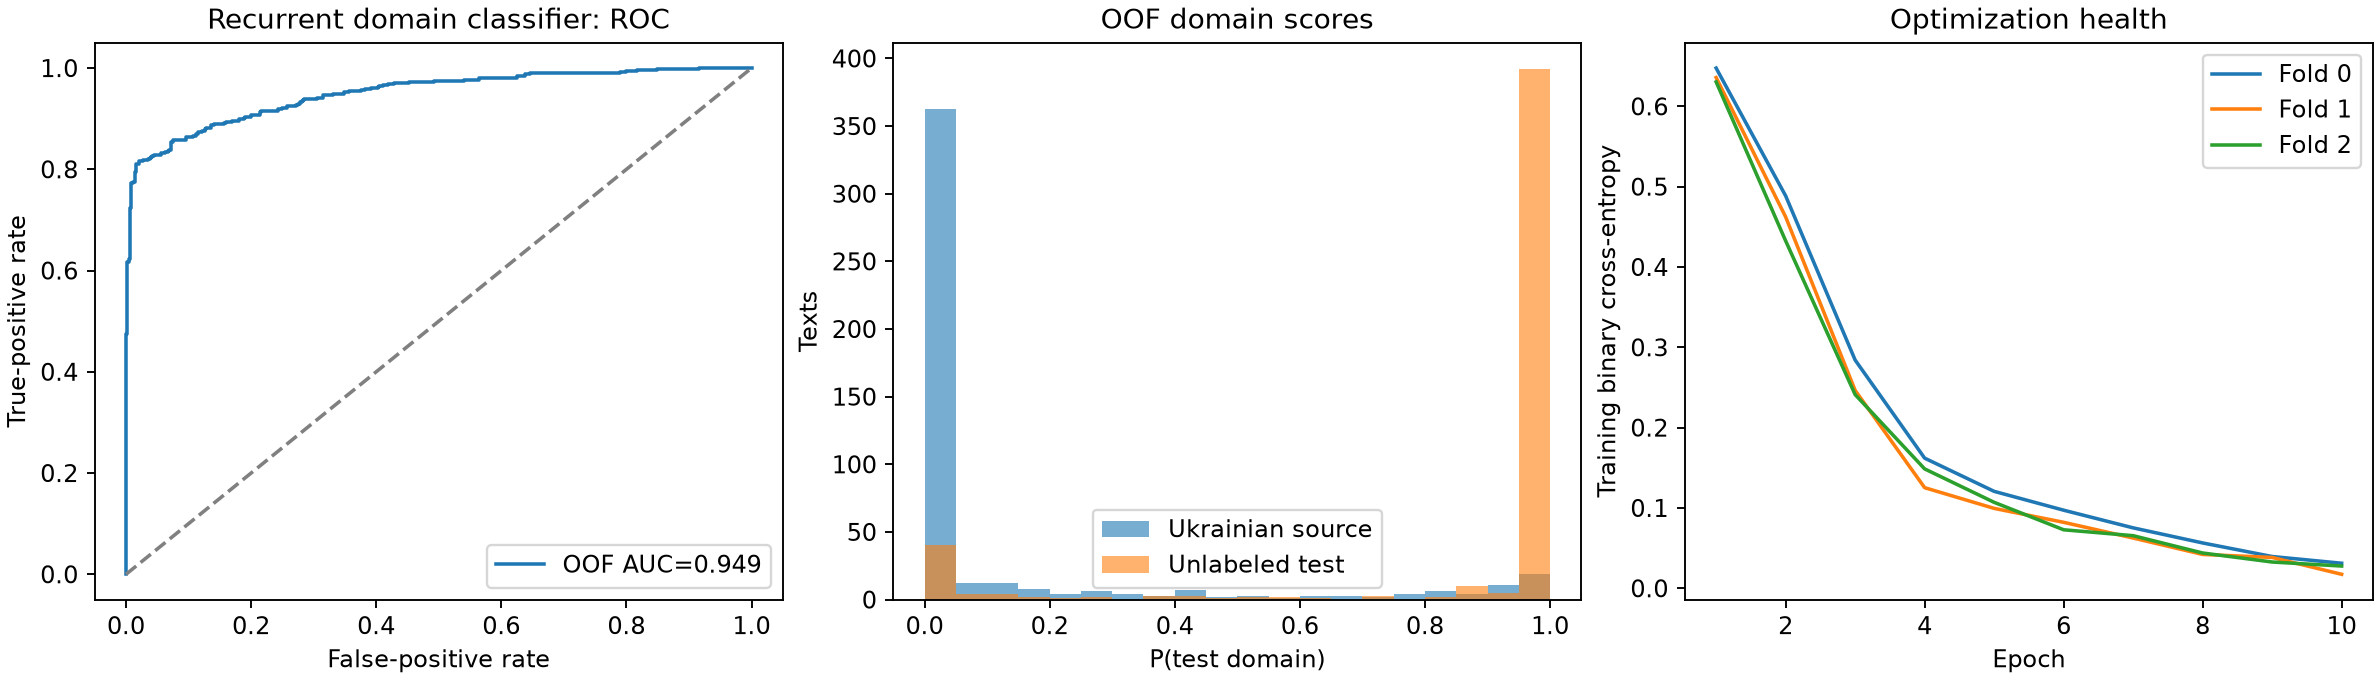

In [3]:
display(Image(filename=str(BASE / 'figures/adversarial_validation.png')))

## Optimization health

Finite loss and gradients were checked during training. Held-out trajectories are diagnostic, not an epoch-selection criterion.

In [4]:
history = pd.read_csv(BASE / 'reports/adversarial_history.csv')
display(history.groupby('fold').tail(1))

,fold,epoch,train_bce,heldout_auc,heldout_bce,mean_gradient_norm
9,0,10,0.031190,0.957676,0.575868,0.214241
19,1,10,0.017434,0.966892,0.426414,0.129410
29,2,10,0.027702,0.978996,0.324147,0.193935


## Reproduce (optional)

The full manifest is in `data/validation_splits.csv`. This recomputes the split and retrains only the adversarial models; it does not train or score NER.

In [ ]:
# import subprocess, sys
# subprocess.run([sys.executable, str(BASE / 'validation.py')], check=True)